# Modularity on the Karate Club Graph
### DSC212: Graph Theory Module

| | |
|---|---|
| **Student name** | `[Shaurya Tiwari]` |
| **Roll number** | `[IMS25192]` |

## 1. Objectives

In this assignment, the objective is to discover groups of people who are more strongly connected to each other than we would expect by chance i.e "Community Detection". The algorithm used to do that uses a mathematical quantity called 'modularity' and the graph used is 'Zachary's Karate Club graph'. It:

1. At each iterations builds the modularity matrix $B$ for all communities (at i=0 the original graph itself) and checks its basic properties;
2. Splits a community in two(Spectral bipartition algorithm) using the sign of the leading eigenvector of its restricted matrix $B^{(C)}=B[C,C]$;
3. Applying the algorithm after each community split to each group until no community has a positive leading eigenvalue (i.e. a usable sign split);
4. Illustrate the full graph after every split, giving each community a different color;
5. Calculate centralities like degree centrality, betweenness centrality, closeness centrality and the clustering coefficient for every node after each split, and plots how each metric evolves;
6. Compares the detected communities after the algorithm finishes;


## 2. Introduction to the Karate Club graph

In the early 1970s the anthropologist Wayne W. Zachary spent two years observing the 34 members of a university karate club and recorded which members interacted outside formal classes. The result is a network with 34 nodes and 78 edges. During the study a dispute between the instructor ("Mr. Hi") and the club administrator (the "Officer") split the club into two factions.

Because the friendships were recorded *before* the split, the graph lets us ask a clean question: **can a method that sees only the graph structure rediscover the social fault line?** The historical faction of each member is stored in the NetworkX dataset, but this notebook does not look at it until the algorithm has finished (Section 19).

## 3. Imports and environment information

In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt


## 4. Load and inspect the dataset

We use the graph shipped with NetworkX. Node IDs `1 … 34` are kept as they are; `node_to_index` makes the mapping between node IDs and matrix rows explicit (here they coincide, but all code goes through the mapping).

**Weights.** In recent NetworkX versions the edges of this graph carry a `weight` attribute. The assignment defines $A_{ij}\in\{0,1\}$ and all four metrics on the *unweighted* graph, so every call below ignores weights (`weight=None`).

In [ ]:
G = nx.karate_club_graph()
G = nx.relabel_nodes(G, {i: i + 1 for i in G.nodes()})

nodes = sorted(G.nodes())                       # original node IDs, in matrix order
node_to_index = {v: i for i, v in enumerate(nodes)}   # node ID -> row/column of A and B
n = G.number_of_nodes()
m = G.number_of_edges()

print(f"Vertices (n)      : {n}")
print(f"Edges (m)         : {m}")
print(f"Directed?         : {G.is_directed()}")
print(f"Connected?        : {nx.is_connected(G)}")
print(f"Edge attributes   : {sorted({key for _, _, d in G.edges(data=True) for key in d})}  (ignored: weight=None)")

assert n == 34 and m == 78 and not G.is_directed() and nx.is_connected(G)

Vertices (n)      : 34
Edges (m)         : 78
Directed?         : False
Connected?        : True
Edge attributes   : ['weight']  (ignored: weight=None)


## 5. Visualise the original graph

The layout is computed **once** with a fixed seed and reused for every figure in the notebook, so communities can be compared from one figure to the next without the nodes moving.

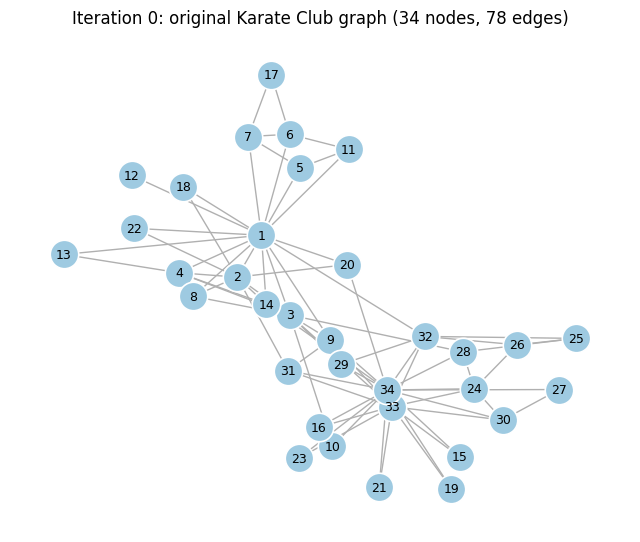

In [ ]:
pos = nx.spring_layout(G, seed=42)      # computed once, reused everywhere

fig, ax = plt.subplots(figsize=(8, 6.5))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#b0b0b0", width=1.0)
nx.draw_networkx_nodes(G, pos, ax=ax, node_color="#9ecae1", node_size=420, edgecolors="white", linewidths=1.2)
nx.draw_networkx_labels(G, pos, ax=ax, font_size=9)
ax.set_title("Iteration 0: original Karate Club graph (34 nodes, 78 edges)")
ax.axis("off")
plt.show()

## 6. Mathematical definition of modularity

Let $A$ be the adjacency matrix, $k_i=\sum_j A_{ij}$ the degree of vertex $i$, $k=(k_1,\dots,k_n)^\top$ the degree vector, $m$ the number of edges (so $\sum_i k_i=2m$) and $n$ the number of vertices.

**Null model.** Give each vertex $k_i$ "stubs" (half-edges) and pair the $2m$ stubs at random. A stub of $i$ hits a stub of $j$ with probability $k_j/2m$, so the *expected* number of edges between $i$ and $j$ is $k_ik_j/2m$.

**Modularity matrix.**
$$
B \;=\; A-\frac{k\,k^\top}{2m},\qquad B_{ij}=A_{ij}-\frac{k_ik_j}{2m}.
$$
$A$ records the edges we **observe**; $kk^\top/2m$ records the edges we would **expect** if edges were placed at random with the same degrees. $B_{ij}>0$ means $i$ and $j$ are connected more than chance predicts.

**Modularity of a bipartition.** For a label vector $s\in\{+1,-1\}^n$,
$$
Q=\frac{1}{4m}\,s^\top B\,s .
$$

**Restricted matrix.** For a candidate community $C$, the assignment defines
$$
B^{(C)}=B[C,C],
$$
i.e. the rows and columns of the *global* $B$ belonging to the nodes of $C$. This is used exactly as defined — no diagonal correction is added.

## 7. Construct and verify the modularity matrix

The code follows the equation line by line: `degrees` is $k$, `np.outer(degrees, degrees)` is $kk^\top$, and dividing by `2*m` gives the expected-edge matrix.

In [ ]:
A = nx.to_numpy_array(G, nodelist=nodes, weight=None, dtype=float)   # A_ij in {0, 1}
degrees = A.sum(axis=1)                                              # k_i = sum_j A_ij
expected_edges = np.outer(degrees, degrees) / (2 * m)                # k k^T / 2m
B = A - expected_edges                                               # B = A - k k^T / 2m

print("A shape:", A.shape, "| B shape:", B.shape)
print("Largest |B - B^T|        :", np.abs(B - B.T).max())
print("Largest |row sum of B|   :", np.abs(B.sum(axis=1)).max(), " (should be ~0, since B·1 = 0)")
print("1^T B 1 (trivial split Q):", float(np.ones(n) @ B @ np.ones(n)), " (should be ~0)")

assert A.shape == (n, n) and B.shape == (n, n)
assert set(np.unique(A)) <= {0.0, 1.0} and np.allclose(A, A.T) and A.sum() == 2 * m
assert np.allclose(degrees, [G.degree(v) for v in nodes])
assert np.allclose(B, B.T)
assert np.allclose(B.sum(axis=1), 0.0)
print("\nAll matrix checks passed.")

A shape: (34, 34) | B shape: (34, 34)
Largest |B - B^T|        : 0.0
Largest |row sum of B|   : 8.881784197001252e-16  (should be ~0, since B·1 = 0)
1^T B 1 (trivial split Q): 3.497202527569243e-15  (should be ~0)

All matrix checks passed.


**What the checks mean.** $B$ is symmetric because $A$ and $kk^\top$ are. Its rows sum to zero because $A\mathbf 1=k$ and $k^\top\mathbf 1=2m$, so $B\mathbf 1=k-k=0$ (Proposition 2 in the handout). Hence placing every node in one community gives $Q=0$ (Corollary 1) — the trivial partition is the baseline against which splits are judged.

## 8. Leading eigenpair and the sign-based split

Searching all $2^n$ label vectors is infeasible, so the problem is **relaxed**: allow $s$ to be any real vector with $\|s\|_2=1$. By the Rayleigh–Ritz theorem,
$$
\max_{\|s\|_2=1}s^\top B s=\lambda_1,
$$
attained at the eigenvector $u_1$ of the largest eigenvalue $\lambda_1$. $u_1$ is a *continuous* "soft assignment": strongly positive entries lean to one side, strongly negative to the other. To get a *discrete* community assignment we threshold by sign:
$$
s_i=\begin{cases}+1,&(u_1)_i>0,\\-1,&(u_1)_i\le 0.\end{cases}
$$
This rounding is a spectral **approximation**; it is not guaranteed to find the best discrete partition.

**Implementation notes**

* `np.linalg.eigh` is for symmetric matrices and returns eigenvalues in *ascending* order, so the leading pair is the last one.
* An eigenvector is only defined up to sign ($u$ and $-u$ are equally valid), which would swap the two children's names. To make the algorithm deterministic, the sign of $u$ is fixed so that its largest-magnitude entry is positive.
* Each community's eigenpair is cached so it is never computed twice.

In [ ]:
eigenpair_cache = {}      # tuple(community nodes) -> (leading eigenvalue, leading eigenvector)

def restricted_modularity_matrix(B, community, node_to_index):
    # B^(C) = B[C, C]: pick the rows and columns of the global B that belong to community C.
    idx = [node_to_index[v] for v in community]
    return B[np.ix_(idx, idx)]

def leading_eigenpair(B_C):
    # Largest eigenvalue and its eigenvector for a real symmetric matrix.
    eigenvalues, eigenvectors = np.linalg.eigh(B_C)      # ascending order
    lam = eigenvalues[-1]
    u = eigenvectors[:, -1].copy()
    u *= np.sign(u[np.argmax(np.abs(u))])                # fix the arbitrary sign (determinism)
    return lam, u

def get_leading_eigenpair(B, community, node_to_index):
    key = tuple(community)
    if key not in eigenpair_cache:
        eigenpair_cache[key] = leading_eigenpair(restricted_modularity_matrix(B, community, node_to_index))
    return eigenpair_cache[key]

def sign_labels(u):
    # s_i = +1 if u_i > 0, else -1
    return np.where(u > 0, 1, -1)

def modularity_of_partition(B, communities, node_to_index, m):
    # Q = (1/2m) * sum over communities of the sum of B_ij inside the community.
    # For a bipartition this equals (1/4m) s^T B s because the entries of B sum to zero.
    total = 0.0
    for community in communities:
        total += restricted_modularity_matrix(B, community, node_to_index).sum()
    return total / (2 * m)

# Demonstration on the whole graph (C = V)
lam1, u1 = get_leading_eigenpair(B, nodes, node_to_index)
s_full = sign_labels(u1)
Q_full_split = s_full @ B @ s_full / (4 * m)
print(f"Leading eigenvalue of B        : {lam1:.4f}")
print(f"Sizes of the +1 / -1 groups    : {(s_full == 1).sum()} / {(s_full == -1).sum()}")
print(f"Q = s^T B s / 4m for this split: {Q_full_split:.4f}")
assert np.isclose(Q_full_split,
                  modularity_of_partition(B, [[v for v, si in zip(nodes, s_full) if si == 1],
                                              [v for v, si in zip(nodes, s_full) if si == -1]], node_to_index, m))

Leading eigenvalue of B        : 4.9771
Sizes of the +1 / -1 groups    : 16 / 18
Q = s^T B s / 4m for this split: 0.3715


## 9. Recursive spectral partitioning

For a community $C$ the algorithm does the following (this is the procedure of Section 3.3 / 4 of the handout):

1. Form $B^{(C)}=B[C,C]$ and compute its leading eigenpair $(\lambda_1^{(C)},u_1^{(C)})$.
2. If $\lambda_1^{(C)}\le 0$ (up to a small numerical tolerance), **stop**: no split of $C$ can have $\Delta Q=\tfrac1{4m}s^\top B^{(C)}s>0$ (Theorem 3).
3. Otherwise split by the sign of $u_1^{(C)}$ into $C^+$ and $C^-$.
4. If one side is empty (all eigenvector entries have the same sign), the sign split is **degenerate**: stop, and record the reason.
5. Otherwise **accept** the split and recurse on $C^+$ and $C^-$.

Communities with fewer than two nodes are never split. The recursion always terminates because every accepted split produces two non-empty, strictly smaller communities.

**Bookkeeping.** The *whole* partition is stored as a dictionary `community_id -> nodes`. After every accepted split the child containing the smallest node ID inherits the parent's ID (so its colour in the plots does not change) and the other child gets a new ID; a full snapshot of the partition is then saved. Every attempted split — accepted or not — is logged.

$\Delta Q_{\text{handout}}=\frac1{4m}s^\top B^{(C)}s$ is the quantity in the handout's Theorem 3, and it is what we log. As an independent check we also compute the actual modularity $Q$ of every snapshot from its definition and verify that it increases at each accepted split.

In [ ]:
EIGEN_TOL = 1e-10      # eigenvalues <= EIGEN_TOL are treated as non-positive

def try_split(community_id, B, node_to_index, m, state):
    # Attempt to split one community; recurse into its children if the split is accepted.
    members = state["partition"][community_id]
    record = {
        "attempt": len(state["split_log"]) + 1,
        "parent_id": community_id,
        "parent_nodes": list(members),
        "parent_size": len(members),
        "leading_eigenvalue": np.nan,
        "delta_Q_handout": np.nan,
        "accepted": False,
        "iteration": None,
        "child_ids": None,
        "child_nodes": None,
        "reason": "",
    }
    state["split_log"].append(record)

    if len(members) < 2:
        record["reason"] = "community has fewer than two nodes"
        return

    lam, u = get_leading_eigenpair(B, members, node_to_index)
    record["leading_eigenvalue"] = lam

    if lam <= EIGEN_TOL:
        record["reason"] = "leading eigenvalue is nonpositive: stop"
        return

    s = sign_labels(u)
    group_plus  = [v for v, si in zip(members, s) if si == 1]
    group_minus = [v for v, si in zip(members, s) if si == -1]

    if len(group_plus) == 0 or len(group_minus) == 0:
        record["reason"] = "degenerate sign split: all eigenvector entries have the same sign"
        return

    B_C = restricted_modularity_matrix(B, members, node_to_index)
    record["delta_Q_handout"] = s @ B_C @ s / (4 * m)

    # Accept the split. The child holding the smallest node ID keeps the parent's ID.
    first, second = sorted([group_plus, group_minus], key=lambda g: min(g))
    new_id = state["next_id"]
    state["next_id"] += 1
    state["iteration"] += 1
    state["partition"][community_id] = sorted(first)
    state["partition"][new_id] = sorted(second)

    record["accepted"] = True
    record["iteration"] = state["iteration"]
    record["child_ids"] = (community_id, new_id)
    record["child_nodes"] = (sorted(first), sorted(second))
    record["reason"] = "lambda_1 > 0 and both sign groups non-empty: split accepted"

    take_snapshot(state, B, node_to_index, m)

    try_split(community_id, B, node_to_index, m, state)    # recurse on the first child
    try_split(new_id, B, node_to_index, m, state)          # recurse on the second child

def take_snapshot(state, B, node_to_index, m):
    partition = {cid: list(members) for cid, members in state["partition"].items()}
    state["snapshots"].append({
        "iteration": state["iteration"],
        "partition": partition,
        "Q": modularity_of_partition(B, list(partition.values()), node_to_index, m),
    })

def recursive_spectral_partition(B, nodes, node_to_index, m):
    state = {"partition": {0: sorted(nodes)}, "next_id": 1, "iteration": 0,
             "snapshots": [], "split_log": []}
    take_snapshot(state, B, node_to_index, m)            # iteration 0: one community = whole graph
    try_split(0, B, node_to_index, m, state)
    return state["snapshots"], state["split_log"]

## 10. Run the algorithm and display the split history

In [ ]:
snapshots, split_log = recursive_spectral_partition(B, nodes, node_to_index, m)

columns = ["attempt", "iteration", "parent_id", "parent_size", "leading_eigenvalue",
           "delta_Q_handout", "accepted", "children", "reason"]
print(" | ".join(columns))
for rec in split_log:
    children = "" if rec["child_nodes"] is None else f"{len(rec['child_nodes'][0])} + {len(rec['child_nodes'][1])}"
    values = [rec["attempt"], rec["iteration"], rec["parent_id"], rec["parent_size"],
              f"{rec['leading_eigenvalue']:.4f}" if np.isfinite(rec["leading_eigenvalue"]) else "nan",
              f"{rec['delta_Q_handout']:.4f}" if np.isfinite(rec["delta_Q_handout"]) else "nan",
              rec["accepted"], children, rec["reason"]]
    print(" | ".join(str(value) for value in values))

print("\nParent / child node lists of the accepted splits:")
for rec in split_log:
    if rec["accepted"]:
        print(f"  Iteration {rec['iteration']}: community {rec['parent_id']} {rec['parent_nodes']}")
        print(f"      -> community {rec['child_ids'][0]}: {rec['child_nodes'][0]}")
        print(f"      -> community {rec['child_ids'][1]}: {rec['child_nodes'][1]}")


attempt | iteration | parent_id | parent_size | leading_eigenvalue | delta_Q_handout | accepted | children | reason
1 | 1 | 0 | 34 | 4.9771 | 0.3715 | True | 16 + 18 | lambda_1 > 0 and both sign groups non-empty: split accepted
2 | 2 | 0 | 16 | 2.9441 | 0.1112 | True | 10 + 6 | lambda_1 > 0 and both sign groups non-empty: split accepted
3 | None | 0 | 10 | 2.5712 | nan | False |  | degenerate sign split: all eigenvector entries have the same sign
4 | 3 | 2 | 6 | 2.1480 | 0.0338 | True | 5 + 1 | lambda_1 > 0 and both sign groups non-empty: split accepted
5 | None | 2 | 5 | 2.1470 | nan | False |  | degenerate sign split: all eigenvector entries have the same sign
6 | None | 3 | 1 | nan | nan | False |  | community has fewer than two nodes
7 | 4 | 1 | 18 | 2.5041 | 0.1112 | True | 13 + 5 | lambda_1 > 0 and both sign groups non-empty: split accepted
8 | None | 1 | 13 | 2.3563 | nan | False |  | degenerate sign split: all eigenvector entries have the same sign
9 | None | 4 | 5 | 1.8759 | n

In [ ]:
snapshot_rows = [{
    "iteration": s["iteration"],
    "num_communities": len(s["partition"]),
    "sizes": sorted((len(v) for v in s["partition"].values()), reverse=True),
    "modularity_Q": s["Q"],
} for s in snapshots]
print("Iteration | Communities | Community sizes   | Modularity Q")
for row in snapshot_rows:
    print(f"{row['iteration']:9} | {row['num_communities']:11} | {str(row['sizes']):15}   | {row['modularity_Q']:.4f}")

# ---- Partition checks -------------------------------------------------------
for i, snap in enumerate(snapshots):
    all_members = [v for members in snap["partition"].values() for v in members]
    assert sorted(all_members) == nodes, f"snapshot {i}: nodes lost or duplicated"
    assert all(len(members) == len(set(members)) > 0 for members in snap["partition"].values())
    assert snap["iteration"] == i
    assert len(snap["partition"]) == i + 1, "each accepted split must add exactly one community"
for rec in split_log:
    if rec["accepted"]:
        assert all(len(c) > 0 for c in rec["child_nodes"])
        assert sorted(rec["child_nodes"][0] + rec["child_nodes"][1]) == sorted(rec["parent_nodes"])
q_values = np.array([row["modularity_Q"] for row in snapshot_rows])
assert np.isclose(q_values[0], 0.0) and np.all(np.diff(q_values) > 0), "Q must increase at every accepted split"

num_splits = len(snapshots) - 1
final_partition = snapshots[-1]["partition"]
print(f"\nAll partition checks passed. Accepted splits: {num_splits}; final communities: {len(final_partition)}; final Q = {q_values[-1]:.4f}")


Iteration | Communities | Community sizes   | Modularity Q
        0 |           1 | [34]              | -0.0000
        1 |           2 | [18, 16]          | 0.3715
        2 |           3 | [18, 10, 6]       | 0.3898
        3 |           4 | [18, 10, 5, 1]    | 0.3911
        4 |           5 | [13, 10, 5, 5, 1]   | 0.4094

All partition checks passed. Accepted splits: 4; final communities: 5; final Q = 0.4094


## 11. Visualise the graph after every accepted split

Each figure shows the **whole** graph with the same node positions as in Section 5. Nodes are coloured by their current community; a community keeps its colour for as long as it exists (when a community splits, the half with the smallest node ID keeps the colour and the other half receives a new one).

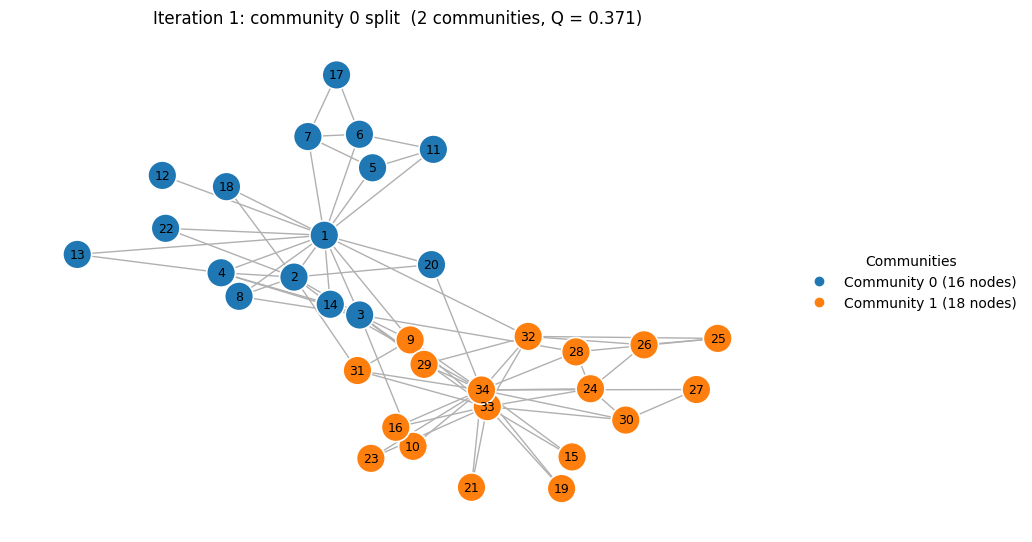

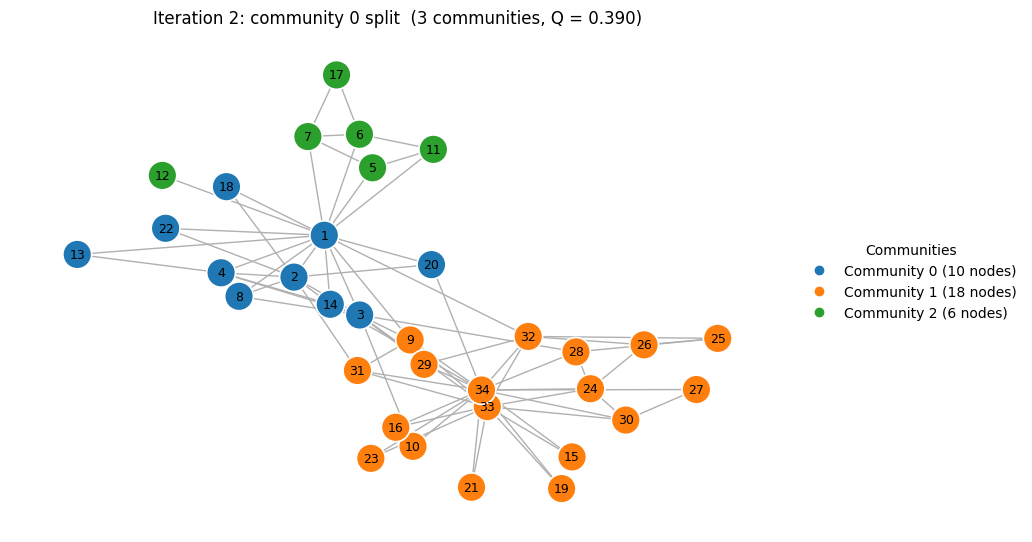

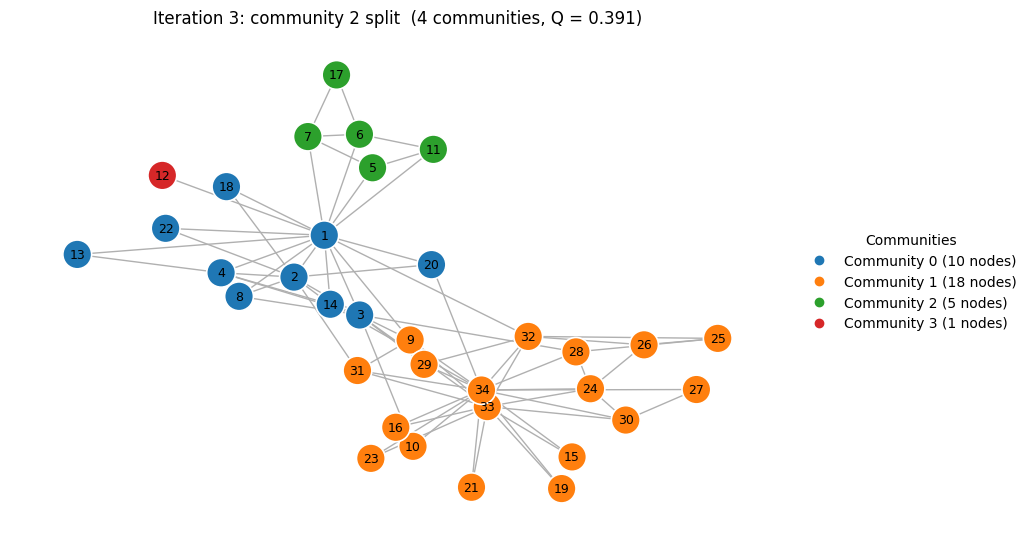

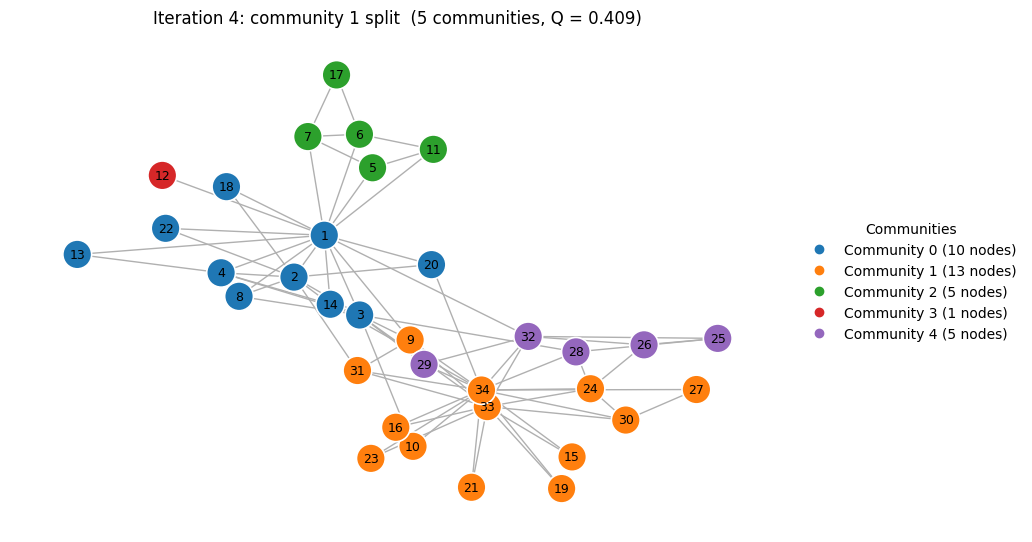

In [ ]:
COMMUNITY_COLORS = plt.get_cmap("tab10").colors      # categorical palette; fixed order by community id

def draw_partition(snapshot, title):
    partition = snapshot["partition"]
    node_color = {}
    for cid, members in partition.items():
        for v in members:
            node_color[v] = COMMUNITY_COLORS[cid % len(COMMUNITY_COLORS)]
    fig, ax = plt.subplots(figsize=(10, 6.5))
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#b0b0b0", width=1.0)
    nx.draw_networkx_nodes(G, pos, ax=ax, nodelist=nodes, node_color=[node_color[v] for v in nodes],
                           node_size=430, edgecolors="white", linewidths=1.2)
    nx.draw_networkx_labels(G, pos, ax=ax, font_size=9)
    handles = [plt.Line2D([], [], marker="o", linestyle="", color=COMMUNITY_COLORS[cid % len(COMMUNITY_COLORS)],
                          label=f"Community {cid} ({len(members)} nodes)")
               for cid, members in partition.items()]
    ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False, title="Communities")
    ax.set_title(title)
    ax.axis("off")
    plt.show()

for snap in snapshots[1:]:
    rec = next(r for r in split_log if r["iteration"] == snap["iteration"])
    draw_partition(snap, f"Iteration {snap['iteration']}: community {rec['parent_id']} split  "
                         f"({len(snap['partition'])} communities, Q = {snap['Q']:.3f})")


## 12. Node metrics at each iteration

The four metrics (computed with NetworkX, unweighted):

| Metric | Definition | Reading |
|---|---|---|
| `nx.degree_centrality` | $C_D(i)=\dfrac{k_i}{r-1}$ ($r$ = number of nodes in the graph considered) | fraction of the other nodes that $i$ is directly linked to |
| `nx.betweenness_centrality` | $C_B(i)=\sum_{s\ne i\ne t}\dfrac{\sigma_{st}(i)}{\sigma_{st}}$ (NetworkX normalises) | how often $i$ lies on shortest paths between other nodes — bridges and brokers |
| `nx.closeness_centrality` | $C_C(i)=\dfrac{r-1}{\sum_{j\ne i}d(i,j)}$ | inverse average distance to the other reachable nodes |
| `nx.clustering` | $C(i)=\dfrac{2T(i)}{k_i(k_i-1)}$ | how interconnected $i$'s neighbours are |

### Methodological decision: within-community metrics

Community detection never deletes edges, so metrics computed on the unchanged graph would be identical at every iteration. To make an *evolution* meaningful, the metrics are computed **within-community**:

* **Iteration 0:** the single community is the whole graph, so these are the ordinary full-graph metrics (the baseline).
* **After each accepted split:** every node's metrics are computed on the subgraph *induced* by the community the node currently belongs to (`G.subgraph(community)`). Nodes in different communities are therefore measured in different, smaller graphs.
* **Final iteration:** metrics within the final detected communities.

These are values on *different subgraphs*, not evidence that the original graph or a node's original degree changed. Because $r$ shrinks, the denominators change as well ($r-1$ in degree and closeness).

**Edge cases.** A singleton community has $r-1=0$, so degree and closeness are undefined; NetworkX would return degree centrality $1$ for a one-node graph, which would be misleading, so we set all four metrics to $0$ for singletons. If an induced community is disconnected, NetworkX's closeness uses the nodes that are reachable (Wasserman–Faust scaling); we report whether this happens.

In [ ]:
METRIC_FUNCTIONS = {
    "degree_centrality":      nx.degree_centrality,
    "betweenness_centrality": nx.betweenness_centrality,
    "closeness_centrality":   nx.closeness_centrality,
    "clustering_coefficient": nx.clustering,
}

def metrics_for_community(H):
    # All four metrics on the (induced) subgraph H. Returns {metric: {node: value}}.
    if H.number_of_nodes() == 1:                       # singleton: set all metrics to 0 (see text)
        only = next(iter(H.nodes))
        return {name: {only: 0.0} for name in METRIC_FUNCTIONS}
    return {name: func(H) for name, func in METRIC_FUNCTIONS.items()}

# metrics_by_iteration[iteration][metric][node] = value   (dictionary keyed by iteration, as in the handout)
metrics_by_iteration = {}
disconnected_communities = []
for snap in snapshots:
    per_metric = {name: {} for name in METRIC_FUNCTIONS}
    for cid, members in snap["partition"].items():
        H = G.subgraph(members)                        # induced subgraph of this community
        if not nx.is_connected(H):
            disconnected_communities.append((snap["iteration"], cid))
        for name, values in metrics_for_community(H).items():
            per_metric[name].update(values)
    metrics_by_iteration[snap["iteration"]] = per_metric

print("Metrics computed for iterations:", list(metrics_by_iteration))
print("Disconnected induced communities (iteration, community id):", disconnected_communities or "none")

Metrics computed for iterations: [0, 1, 2, 3, 4]
Disconnected induced communities (iteration, community id): [(2, 2)]


## 13. Store and inspect the metric history (long format)

In [ ]:
node_community = {snap["iteration"]: {v: cid for cid, members in snap["partition"].items() for v in members}
                  for snap in snapshots}

rows = []
for iteration, per_metric in metrics_by_iteration.items():
    for metric, values in per_metric.items():
        for node, value in values.items():
            rows.append({"iteration": iteration,
                         "community_id": node_community[iteration][node],
                         "node": node, "metric": metric, "value": value})
metric_history = sorted(rows, key=lambda row: (row["iteration"], row["metric"], row["node"]))

print("First 8 metric-history rows:")
for row in metric_history[:8]:
    print(row)
print("\n8 reproducibly selected metric-history rows:")
for index in np.linspace(0, len(metric_history) - 1, 8, dtype=int):
    print(metric_history[index])

# ---- Metric checks ------------------------------------------------------------
expected_rows = len(snapshots) * n * len(METRIC_FUNCTIONS)
assert len(metric_history) == expected_rows, (len(metric_history), expected_rows)
keys = [(row["iteration"], row["node"], row["metric"]) for row in metric_history]
assert len(keys) == len(set(keys))
assert all(np.isfinite(row["value"]) and 0 <= row["value"] <= 1 for row in metric_history)
assert set(row["metric"] for row in metric_history) == set(METRIC_FUNCTIONS)
assert set(row["node"] for row in metric_history) == set(nodes)

# baseline = NetworkX applied directly to the full graph G
for name, func in METRIC_FUNCTIONS.items():
    direct = func(G)
    stored = {row["node"]: row["value"] for row in metric_history
              if row["iteration"] == 0 and row["metric"] == name}
    assert all(np.isclose(direct[v], stored[v]) for v in nodes), f"baseline mismatch: {name}"

# last iteration = NetworkX applied directly to each final community's induced subgraph
last = snapshots[-1]
for name, func in METRIC_FUNCTIONS.items():
    stored = {row["node"]: row["value"] for row in metric_history
              if row["iteration"] == last["iteration"] and row["metric"] == name}
    for members in last["partition"].values():
        if len(members) > 1:
            direct = func(G.subgraph(members))
            assert all(np.isclose(direct[v], stored[v]) for v in members), f"final mismatch: {name}"
        else:
            assert stored[members[0]] == 0.0

print(f"\nTable size: {len(metric_history)} rows = {len(snapshots)} iterations x {n} nodes x {len(METRIC_FUNCTIONS)} metrics")
print("All metric checks passed.")


First 8 metric-history rows:
{'iteration': 0, 'community_id': 0, 'node': 1, 'metric': 'betweenness_centrality', 'value': 0.43763528138528146}
{'iteration': 0, 'community_id': 0, 'node': 2, 'metric': 'betweenness_centrality', 'value': 0.053936688311688304}
{'iteration': 0, 'community_id': 0, 'node': 3, 'metric': 'betweenness_centrality', 'value': 0.14365680615680618}
{'iteration': 0, 'community_id': 0, 'node': 4, 'metric': 'betweenness_centrality', 'value': 0.011909271284271283}
{'iteration': 0, 'community_id': 0, 'node': 5, 'metric': 'betweenness_centrality', 'value': 0.0006313131313131313}
{'iteration': 0, 'community_id': 0, 'node': 6, 'metric': 'betweenness_centrality', 'value': 0.02998737373737374}
{'iteration': 0, 'community_id': 0, 'node': 7, 'metric': 'betweenness_centrality', 'value': 0.029987373737373736}
{'iteration': 0, 'community_id': 0, 'node': 8, 'metric': 'betweenness_centrality', 'value': 0.0}

8 reproducibly selected metric-history rows:
{'iteration': 0, 'community_id':

## 14–17. Evolution of the four metrics

One figure per metric. Every line is one node (original node ID); the horizontal axis lists the actual iteration numbers; all values come from `metric_history`. The 34 lines are separated by colour and line style, with the legend outside the plot area. Where several nodes have identical values their lines overlap.

In [ ]:
LINE_COLORS = plt.get_cmap("tab20").colors
def node_style(v):
    return {"color": LINE_COLORS[v % 20], "linestyle": "-" if v < 20 else "--"}

def plot_metric_evolution(metric, title, ylabel):
    iterations = [snap["iteration"] for snap in snapshots]
    wide = {iteration: {v: None for v in nodes} for iteration in iterations}
    for row in metric_history:
        if row["metric"] == metric:
            wide[row["iteration"]][row["node"]] = row["value"]

    fig, ax = plt.subplots(figsize=(12, 6.5))
    for v in nodes:
        values = [wide[iteration][v] for iteration in iterations]
        ax.plot(iterations, values, marker="o", markersize=4, linewidth=1.3,
                label=str(v), **node_style(v))
    ax.set_xticks(iterations)
    ax.set_xlabel("Accepted split iteration (0 = whole graph)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, color="#dddddd", linewidth=0.7)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.legend(title="Node", loc="center left", bbox_to_anchor=(1.01, 0.5), ncol=3, fontsize=8, frameon=False)
    plt.tight_layout()
    plt.show()
    return wide


### 14. Degree centrality

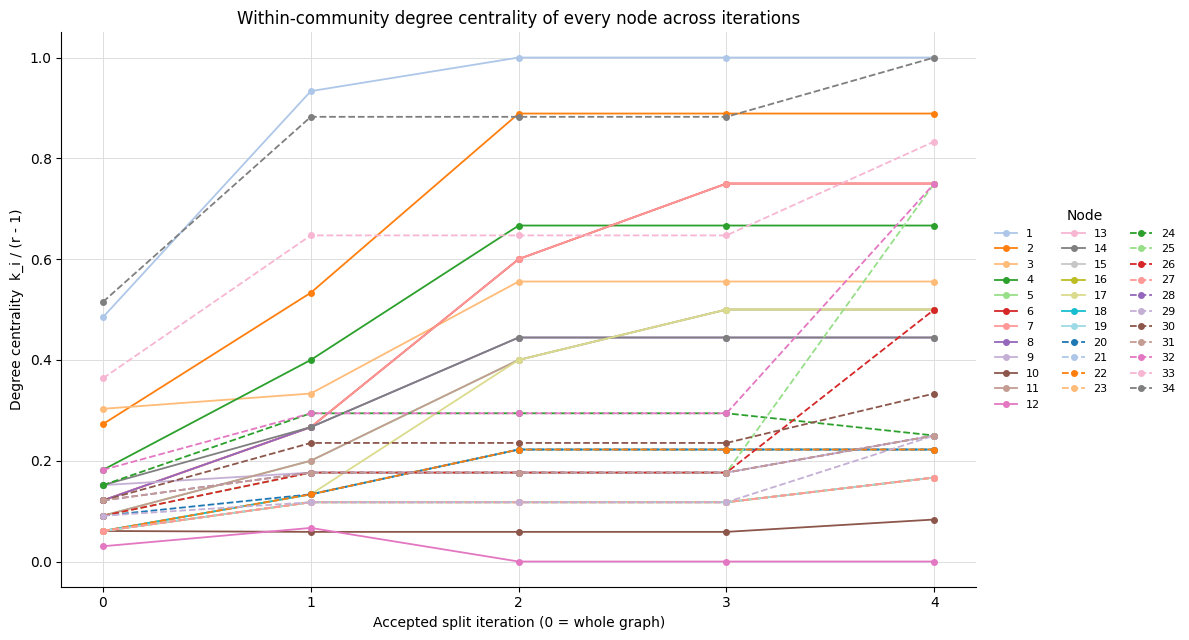

In [ ]:
wide_degree = plot_metric_evolution("degree_centrality",
    "Within-community degree centrality of every node across iterations", "Degree centrality  k_i / (r - 1)")

### 15. Betweenness centrality

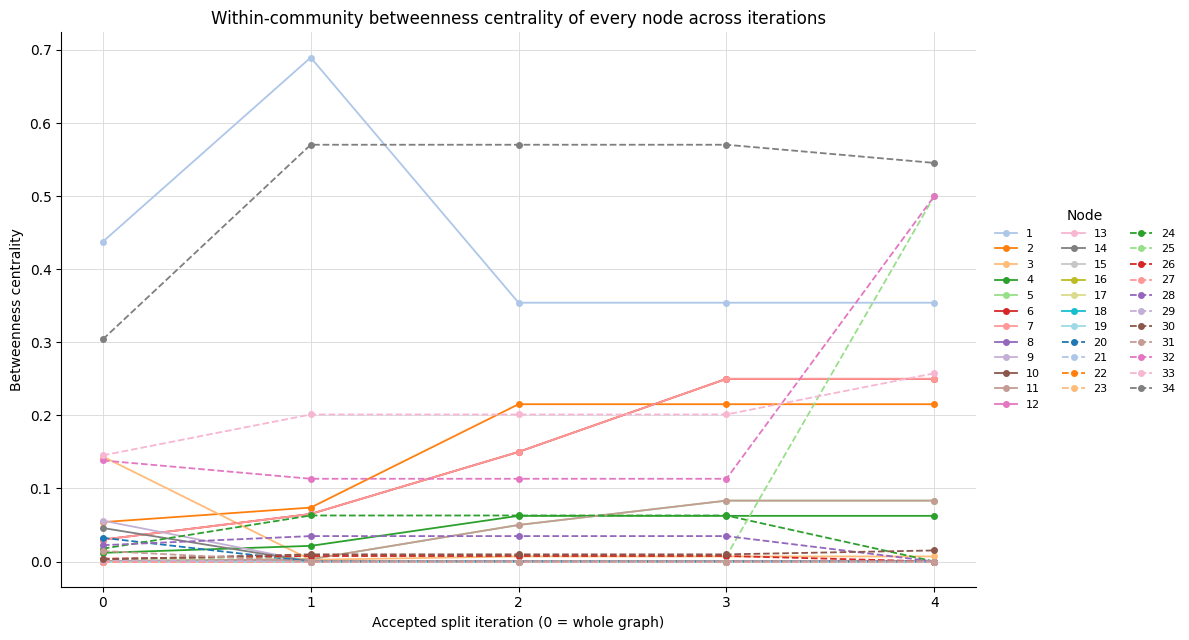

In [ ]:
wide_betweenness = plot_metric_evolution("betweenness_centrality",
    "Within-community betweenness centrality of every node across iterations", "Betweenness centrality")

### 16. Closeness centrality

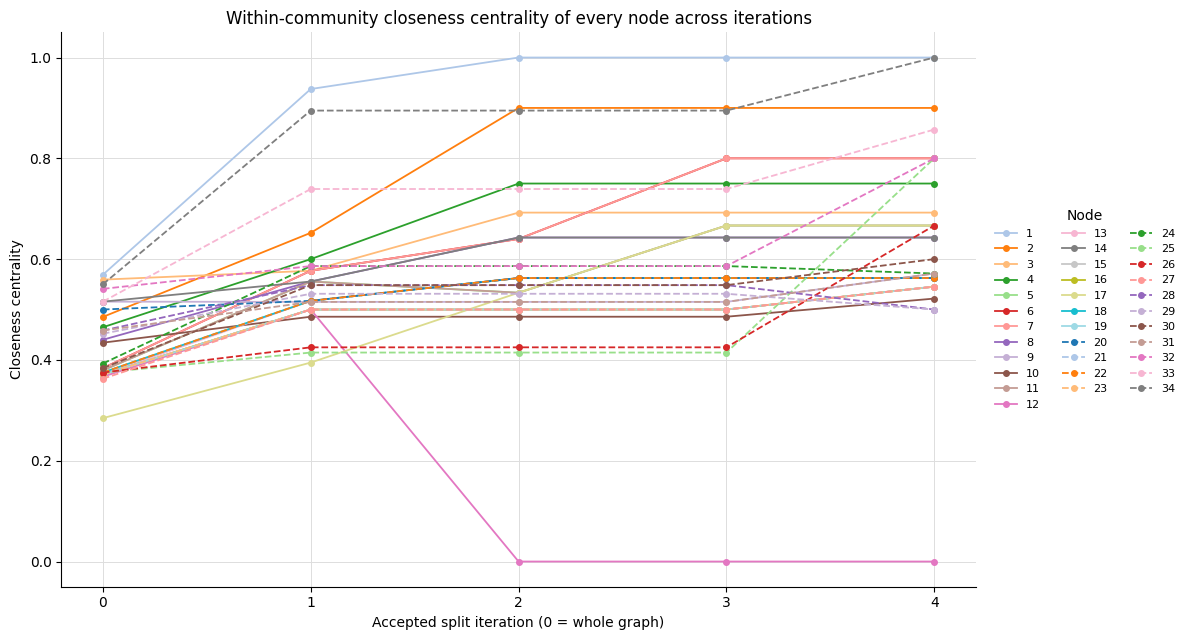

In [ ]:
wide_closeness = plot_metric_evolution("closeness_centrality",
    "Within-community closeness centrality of every node across iterations", "Closeness centrality")

### 17. Clustering coefficient

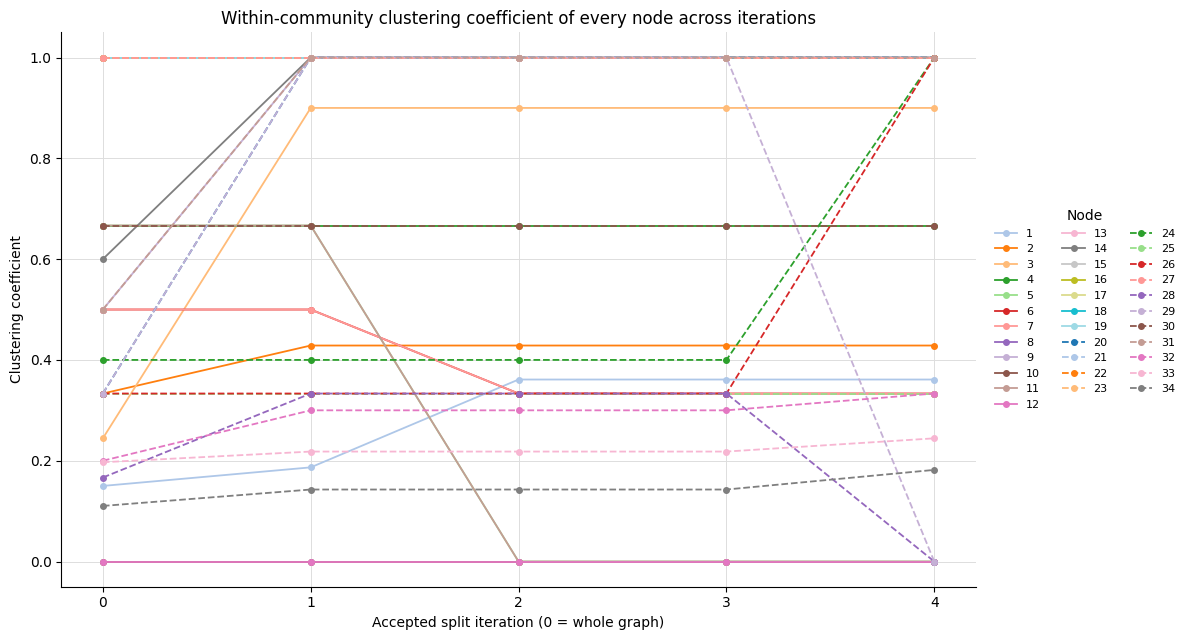

Plot data match the stored metric history.


In [ ]:
wide_clustering = plot_metric_evolution("clustering_coefficient",
    "Within-community clustering coefficient of every node across iterations", "Clustering coefficient")

# The plotted data are exactly the stored history
for wide, name in [(wide_degree, "degree_centrality"), (wide_betweenness, "betweenness_centrality"),
                   (wide_closeness, "closeness_centrality"), (wide_clustering, "clustering_coefficient")]:
    sub = [row for row in metric_history if row["metric"] == name]
    assert len(wide) == len(snapshots) and all(len(wide[it]) == n for it in wide)
    assert np.isclose(sum(value for iteration in wide for value in wide[iteration].values()),
                      sum(row["value"] for row in sub))
print("Plot data match the stored metric history.")


## 18. Baseline (full graph) versus final (within final community) metrics

In [ ]:
final_iter = snapshots[-1]["iteration"]
metric_names = list(METRIC_FUNCTIONS)
base = {metric: {row["node"]: row["value"] for row in metric_history
                 if row["iteration"] == 0 and row["metric"] == metric}
        for metric in metric_names}
final = {metric: {row["node"]: row["value"] for row in metric_history
                  if row["iteration"] == final_iter and row["metric"] == metric}
         for metric in metric_names}

print("Node | Final community | Metric | Baseline | Final within-community | Change")
for node in nodes:
    cid = node_community[final_iter][node]
    for metric in metric_names:
        before, after = base[metric][node], final[metric][node]
        print(f"{node:4} | {cid:15} | {metric:24} | {before:8.3f} | {after:22.3f} | {after-before:7.3f}")

deg_change = {node: final["degree_centrality"][node] - base["degree_centrality"][node] for node in nodes}
ordered_deg_change = sorted(deg_change.items(), key=lambda item: item[1])
print("\nDegree centrality change (final within-community minus full-graph baseline):")
print("  largest increases:", {node: round(change, 3) for node, change in ordered_deg_change[-5:]})
print("  only decreases   :", {node: round(change, 3) for node, change in ordered_deg_change if change < 0})


Node | Final community | Metric | Baseline | Final within-community | Change
   1 |               0 | degree_centrality        |    0.485 |                  1.000 |   0.515
   1 |               0 | betweenness_centrality   |    0.438 |                  0.354 |  -0.083
   1 |               0 | closeness_centrality     |    0.569 |                  1.000 |   0.431
   1 |               0 | clustering_coefficient   |    0.150 |                  0.361 |   0.211
   2 |               0 | degree_centrality        |    0.273 |                  0.889 |   0.616
   2 |               0 | betweenness_centrality   |    0.054 |                  0.215 |   0.161
   2 |               0 | closeness_centrality     |    0.485 |                  0.900 |   0.415
   2 |               0 | clustering_coefficient   |    0.333 |                  0.429 |   0.095
   3 |               0 | degree_centrality        |    0.303 |                  0.556 |   0.253
   3 |               0 | betweenness_centrality   |    0.14

## 19. Detected communities versus the historical factions

Only now, after the algorithm has finished, do we read the historical `club` label stored in the dataset (`Mr. Hi` or `Officer`). These labels played **no role** in the matrix, the eigenvectors, the thresholds or the recursion.

Detected communities and historical factions are different things: the algorithm optimises the modularity objective, not agreement with the historical split, so there is no reason for it to reproduce the factions exactly. We summarise the agreement with the adjusted Rand index (ARI), implemented here with NumPy to avoid an extra dependency: ARI is $1$ for identical groupings and about $0$ for chance-level agreement.

In [ ]:
club = {v: G.nodes[v]["club"] for v in nodes}
factions = sorted(set(club.values()))

rows = []
for cid, members in snapshots[-1]["partition"].items():
    row = {"detected community": cid, "size": len(members)}
    for f in factions:
        row[f"# {f}"] = sum(club[v] == f for v in members)
    row["nodes"] = members
    rows.append(row)
print("Detected community versus historical faction counts:")
for row in rows:
    print(row)

def adjusted_rand_index(labels_a, labels_b):
    a_vals, a_idx = np.unique(labels_a, return_inverse=True)
    b_vals, b_idx = np.unique(labels_b, return_inverse=True)
    table = np.zeros((len(a_vals), len(b_vals)))
    for i, j in zip(a_idx, b_idx):
        table[i, j] += 1
    comb2 = lambda x: x * (x - 1) / 2
    sum_cells = comb2(table).sum()
    sum_rows, sum_cols = comb2(table.sum(axis=1)).sum(), comb2(table.sum(axis=0)).sum()
    expected = sum_rows * sum_cols / comb2(len(labels_a))
    return (sum_cells - expected) / (0.5 * (sum_rows + sum_cols) - expected)

historical = [club[v] for v in nodes]
for snap in (snapshots[1], snapshots[-1]):
    labels = [node_community[snap["iteration"]][v] for v in nodes]
    print(f"ARI vs historical factions, iteration {snap['iteration']} ({len(snap['partition'])} communities): "
          f"{adjusted_rand_index(labels, historical):.3f}")

# How does the very first split (two communities) compare with the factions?
first_split = snapshots[1]["partition"]
majority = {cid: max(factions, key=lambda f: sum(club[v] == f for v in members)) for cid, members in first_split.items()}
mismatched = sorted(v for cid, members in first_split.items() for v in members if club[v] != majority[cid])
print(f"\nFirst split: community 0 is mostly '{majority[0]}', community 1 is mostly '{majority[1]}'.")
print(f"Nodes whose historical faction differs from their community's majority faction: {mismatched}")


Detected community versus historical faction counts:
{'detected community': 0, 'size': 10, '# Mr. Hi': 10, '# Officer': 0, 'nodes': [1, 2, 3, 4, 8, 13, 14, 18, 20, 22]}
{'detected community': 1, 'size': 13, '# Mr. Hi': 1, '# Officer': 12, 'nodes': [9, 10, 15, 16, 19, 21, 23, 24, 27, 30, 31, 33, 34]}
{'detected community': 2, 'size': 5, '# Mr. Hi': 5, '# Officer': 0, 'nodes': [5, 6, 7, 11, 17]}
{'detected community': 3, 'size': 1, '# Mr. Hi': 1, '# Officer': 0, 'nodes': [12]}
{'detected community': 4, 'size': 5, '# Mr. Hi': 0, '# Officer': 5, 'nodes': [25, 26, 28, 29, 32]}
ARI vs historical factions, iteration 1 (2 communities): 0.882
ARI vs historical factions, iteration 4 (5 communities): 0.446

First split: community 0 is mostly 'Mr. Hi', community 1 is mostly 'Officer'.
Nodes whose historical faction differs from their community's majority faction: [9]


### Key numbers used in the discussion
The next cell prints the figures that the discussion below refers to, so every statement can be traced to an output.

In [ ]:
def top(wide, iteration, k=5):
    return dict(sorted(wide[iteration].items(), key=lambda item: item[1], reverse=True)[:k])

def rounded_dict(values, digits=3):
    return {node: round(value, digits) for node, value in values.items()}

print("Iteration 0 (full graph)")
print("  top degree centrality    :", rounded_dict(top(wide_degree, 0)))
print("  top betweenness          :", rounded_dict(top(wide_betweenness, 0)))
print("  top closeness            :", rounded_dict(top(wide_closeness, 0)))
print("  top clustering           :", rounded_dict(top(wide_clustering, 0)))
print(f"\nFinal iteration ({final_iter})")
print("  top degree centrality    :", rounded_dict(top(wide_degree, final_iter)))
print("  top betweenness          :", rounded_dict(top(wide_betweenness, final_iter)))
print("  top closeness            :", rounded_dict(top(wide_closeness, final_iter)))
print("  top clustering           :", rounded_dict(top(wide_clustering, final_iter)))

print("\nBetweenness of nodes 1 and 34 by iteration:")
for iteration in sorted(wide_betweenness):
    print(iteration, {node: round(wide_betweenness[iteration][node], 3) for node in (1, 34)})
print("\nDegree centrality of nodes 1 and 34 by iteration:")
for iteration in sorted(wide_degree):
    print(iteration, {node: round(wide_degree[iteration][node], 3) for node in (1, 34)})

print("\nClustering: nodes that increased / decreased / stayed the same (baseline -> final)")
delta_c = {node: wide_clustering[final_iter][node] - wide_clustering[0][node] for node in nodes}
print("  increased:", sorted(node for node, change in delta_c.items() if change > 1e-6))
print("  decreased:", sorted(node for node, change in delta_c.items() if change < -1e-6))
print("  unchanged:", sorted(node for node, change in delta_c.items() if abs(change) <= 1e-6))
print("Singleton communities at the end:", [m_[0] for m_ in snapshots[-1]['partition'].values() if len(m_) == 1])


Iteration 0 (full graph)
  top degree centrality    : {34: 0.515, 1: 0.485, 33: 0.364, 3: 0.303, 2: 0.273}
  top betweenness          : {1: 0.438, 34: 0.304, 33: 0.145, 3: 0.144, 32: 0.138}
  top closeness            : {1: 0.569, 3: 0.559, 34: 0.55, 32: 0.541, 9: 0.516}
  top clustering           : {8: 1.0, 13: 1.0, 15: 1.0, 16: 1.0, 17: 1.0}

Final iteration (4)
  top degree centrality    : {1: 1.0, 34: 1.0, 2: 0.889, 33: 0.833, 6: 0.75}
  top betweenness          : {34: 0.545, 25: 0.5, 32: 0.5, 1: 0.354, 33: 0.258}
  top closeness            : {1: 1.0, 34: 1.0, 2: 0.9, 33: 0.857, 6: 0.8}
  top clustering           : {8: 1.0, 9: 1.0, 13: 1.0, 14: 1.0, 15: 1.0}

Betweenness of nodes 1 and 34 by iteration:
0 {1: 0.438, 34: 0.304}
1 {1: 0.69, 34: 0.57}
2 {1: 0.354, 34: 0.57}
3 {1: 0.354, 34: 0.57}
4 {1: 0.354, 34: 0.545}

Degree centrality of nodes 1 and 34 by iteration:
0 {1: 0.485, 34: 0.515}
1 {1: 0.933, 34: 0.882}
2 {1: 1.0, 34: 0.882}
3 {1: 1.0, 34: 0.882}
4 {1: 1.0, 34: 1.0}

Clust

## 20. Discussion and conclusion

All figures quoted below come from the outputs above (Sections 10–19). The metrics from iteration 1 onward are **within-community** values, so they describe a node's position inside its current community and not a change in the original graph.

### What the algorithm found
Using $B^{(C)}=B[C,C]$ exactly as in the handout, the recursion made **4 accepted splits** and ended with **5 communities** of sizes 13, 10, 5, 5 and 1. The modularity of the partition rose from $0$ (everything in one community) to $0.3715$ after the first split, then $0.3898$, $0.3911$ and finally $0.4094$. Four communities were not split further even though their leading eigenvalue was still positive ($\lambda_1\approx2.57,\,2.36,\,2.15,\,1.88$): every entry of their leading eigenvector had the same sign, so the sign rule gave no usable bipartition (these are logged as "degenerate sign split" in Section 10).

### 1. Which nodes stay central
* In the original graph the highest degree centrality belongs to **node 34 (0.515)** and **node 1 (0.485)**, followed by 33, 3 and 2. Betweenness gives a different order: **node 1 (0.438)** is first, then 34 (0.304), 33 (0.145), **3 (0.144)** and 32 (0.138). So degree and betweenness do not identify exactly the same nodes. Node 3 is 4th by degree and 4th by betweenness but 2nd by closeness (0.559); node 32 is 4th by closeness and 5th by betweenness while having a much lower degree (0.182). Such nodes sit on many shortest paths without being the biggest hubs.
* **Nodes 1 and 34** are the most consistently central nodes. They are at or near the top for degree and closeness at every iteration and both end with degree and closeness equal to 1 inside their final communities (every other member of the community is a direct neighbour). The one exception is iterations 2–3, where node 2 (degree 0.889) is marginally ahead of node 34 (0.882). **Node 33** also stays in the upper group (degree 0.364 → 0.833).
* Other nodes become "central" only because their community is small: in the final 5-node community nodes 25 and 32 reach betweenness 0.5 (from 0.002 and 0.138). That reflects the small community, not importance in the whole club.

### 2. How the metrics change across iterations
* **Degree centrality** is $k_i^{(C)}/(r-1)$ with $r=|C|$. A node can lose neighbours yet gain centrality because the denominator shrinks faster: node 1 has 16 neighbours in the full graph (0.485) but only 9 in its final community, where it is adjacent to all 9 others (1.0). Almost every node's value rises; the only decrease is the singleton node 12 (0.030 → 0).
* **Betweenness** changes because shortest paths are now computed only inside the community. Node 1 jumps from 0.438 to 0.690 at iteration 1 (it is the hub of a smaller graph) and falls to 0.354 once nodes 5, 6, 7, 11, 12, 17 leave its community. Node 3 drops from 0.144 to 0.002 at iteration 1: it has several neighbours in the other community, so once the graph is cut its shortest paths no longer run through it.
* **Closeness** generally rises because distances are measured within a smaller, denser group (node 1: 0.569 → 1.0). Node 12 shows the edge case: its only neighbour is node 1, so in the 6-node community $\{5,6,7,11,12,17\}$ (iteration 2) it is isolated (this induced community is disconnected) and its closeness falls to 0.
* **Clustering** goes up for some nodes and down for others because it depends on which of a node's neighbours remain in the community. Node 29 goes from 0.333 to 1.0 at iteration 1 (its remaining neighbours are all linked), but to 0 at the end because only one neighbour is left in its final community. Node 5 drops from 0.667 to 0 at iteration 2 because its two remaining neighbours (7 and 11) are not adjacent. Overall, 12 nodes end with a higher clustering coefficient, 6 with a lower one and 16 are unchanged.

### 3. Community structure and the historical factions
The first split (16 + 18 nodes) agrees with the real split of the club very closely: **only node 8 differs** from its community's majority faction (adjusted Rand index $0.882$). The later splits refine each faction rather than cut across it: of the five final communities, four contain members of one faction only, and the fifth (13 nodes) contains the same node 8 plus 12 `Officer` members. The final ARI is lower ($0.446$) only because a 5-community partition is compared with a 2-faction labelling. The recursive method therefore suggests that the factions have internal sub-groups (for example the group $\{5,6,7,11,17\}$ and the group $\{25,26,28,29,32\}$), but the data alone cannot say whether these sub-groups were socially meaningful.

### 4. Limitations
* Sign thresholding is a spectral **approximation** to a discrete optimisation problem; it does not guarantee the best partition, and it fails to produce a split in the four degenerate cases above.
* The results depend on the formulation. I used $B^{(C)}=B[C,C]$ as required. A common variant (Newman, 2006) subtracts a diagonal term from $B^{(C)}$; with the handout's matrix the logged $\Delta Q=\frac1{4m}s^\top B^{(C)}s$ (0.372, 0.111, 0.034, 0.111) is larger than the real change in modularity for the sub-splits (0.018, 0.001, 0.018). The real $Q$ still increased at every accepted split here, but this is something I checked, not something the criterion guarantees.
* The algorithm optimises modularity, not agreement with the historical labels, so it need not reproduce them.
* Centrality values depend on the graph they are computed in: a within-community value of 1.0 and a full-graph value of 1.0 mean very different things, and values from communities of different sizes are not directly comparable.
* Very small communities (a singleton, or a pair) give little information; the singleton's metrics were set to 0 by convention.

## 21. References

1. Newman, M. E. J. (2006). "Modularity and community structure in networks." *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582.
2. Zachary, W. W. (1977). "An information flow model for conflict and fission in small groups." *Journal of Anthropological Research*, 33(4), 452–473. (Original source of the Karate Club data, also described in the assignment handout.)

The mathematical development (modularity matrix, restricted matrix $B^{(C)}$, Rayleigh–Ritz relaxation, sign thresholding, eigenvalue stopping criterion) follows the DSC212 assignment handout, which is based on Newman (2006).